In [1]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

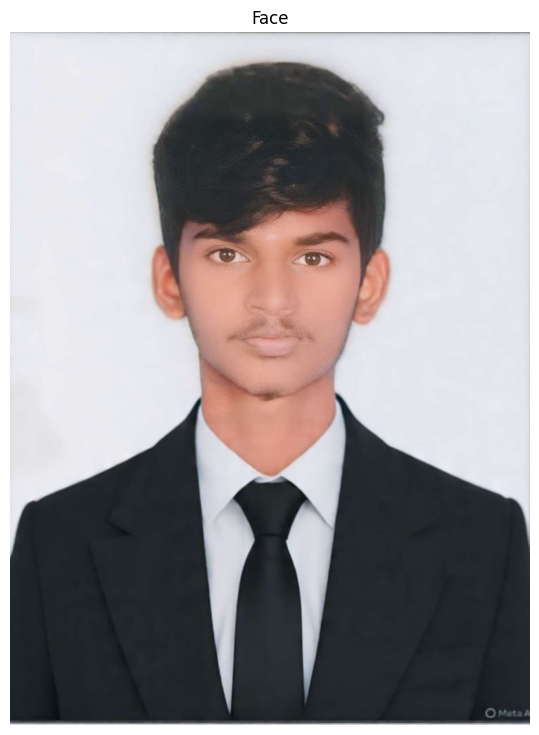

In [2]:
# Load the Face Image
faceImage = cv2.imread('1.jpeg')
if faceImage is None:
    raise FileNotFoundError("Place the face image '1.jpeg' in the notebook folder.")
plt.figure(figsize=(7, 9))
plt.imshow(cv2.cvtColor(faceImage, cv2.COLOR_BGR2RGB))
plt.title("Face")
plt.axis("off")
plt.show()

In [3]:
faceImage.shape

(1407, 1055, 3)

In [4]:
#resized_faceImage.shape
faceImage.shape

(1407, 1055, 3)

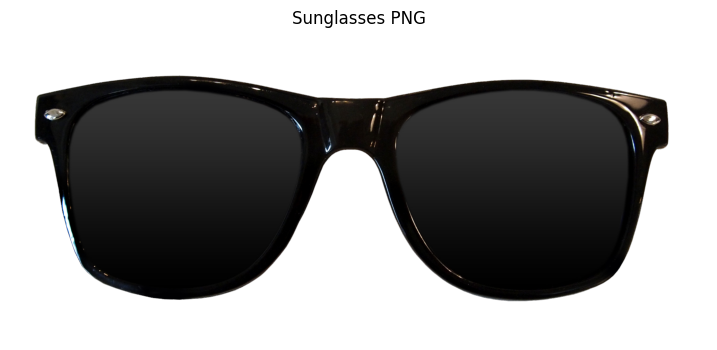

In [5]:
# Load the Sunglass image with Alpha channel
# Use the uploaded filename. Keep this PNG in the notebook folder.
glassPNG = cv2.imread('sunglass (1).png', cv2.IMREAD_UNCHANGED)
if glassPNG is None:
    raise FileNotFoundError("Place 'sunglass (1).png' in the notebook folder.")
if glassPNG.ndim != 3 or glassPNG.shape[2] != 4:
    raise ValueError("The sunglasses image must be a PNG with an alpha channel.")
plt.figure(figsize=(10, 4))
plt.imshow(cv2.cvtColor(glassPNG, cv2.COLOR_BGRA2RGBA))
plt.title("Sunglasses PNG")
plt.axis("off")
plt.show()

In [6]:
# Crop transparent margins, then resize to fit the eyes in the supplied face photo
alpha_channel = glassPNG[:, :, 3]
ys, xs = cv2.findNonZero((alpha_channel > 10).astype('uint8')), None
# Find the bounding rectangle of the visible sunglasses (ignore transparent padding)
coords = cv2.findNonZero((alpha_channel > 10).astype('uint8'))
if coords is None:
    raise ValueError("The sunglasses PNG appears to be fully transparent.")
x, y, w, h = cv2.boundingRect(coords)
glassPNG = glassPNG[y:y+h, x:x+w]

# Coordinates tuned for the supplied 1055 x 1407 portrait.
# The visible frame is about 430 px wide; keep its original aspect ratio.
glasses_width = int(faceImage.shape[1] * 0.408)
glasses_height = int(glasses_width * glassPNG.shape[0] / glassPNG.shape[1])
glassPNG = cv2.resize(glassPNG, (glasses_width, glasses_height), interpolation=cv2.INTER_AREA)
print("Sunglasses dimensions = {}".format(glassPNG.shape))

Sunglasses dimensions = (153, 430, 4)


In [7]:
# Separate the Color and alpha channels
glassBGR = glassPNG[:, :, :3]
glassMask1 = glassPNG[:, :, 3]


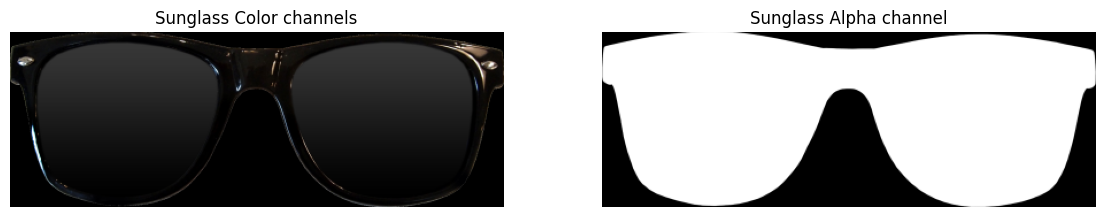

In [8]:
# Display the images for clarity
plt.figure(figsize=[14, 5])
plt.subplot(121); plt.imshow(cv2.cvtColor(glassBGR, cv2.COLOR_BGR2RGB)); plt.title('Sunglass Color channels'); plt.axis('off')
plt.subplot(122); plt.imshow(glassMask1, cmap='gray'); plt.title('Sunglass Alpha channel'); plt.axis('off')
plt.show()

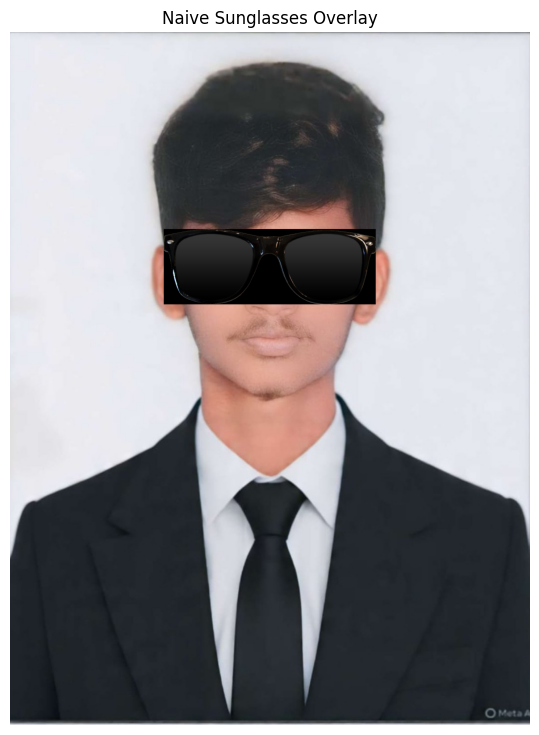

In [9]:
# Make a copy and place the sunglasses over the eye region
faceWithGlassesNaive = faceImage.copy()

# Position tuned for the supplied portrait. Adjust these only if using another face.
x1 = int(faceImage.shape[1] * 0.296)
y1 = int(faceImage.shape[0] * 0.285)
x2 = x1 + glassPNG.shape[1]
y2 = y1 + glassPNG.shape[0]

if x2 > faceImage.shape[1] or y2 > faceImage.shape[0]:
    raise ValueError("Sunglasses placement is outside the face image. Reduce glasses_width or adjust x1/y1.")

# Simple overlay (includes the PNG's black transparent-area pixels); kept as an intermediate output
faceWithGlassesNaive[y1:y2, x1:x2] = glassBGR
plt.figure(figsize=(7, 9))
plt.imshow(cv2.cvtColor(faceWithGlassesNaive, cv2.COLOR_BGR2RGB))
plt.title("Naive Sunglasses Overlay")
plt.axis('off')
plt.show()

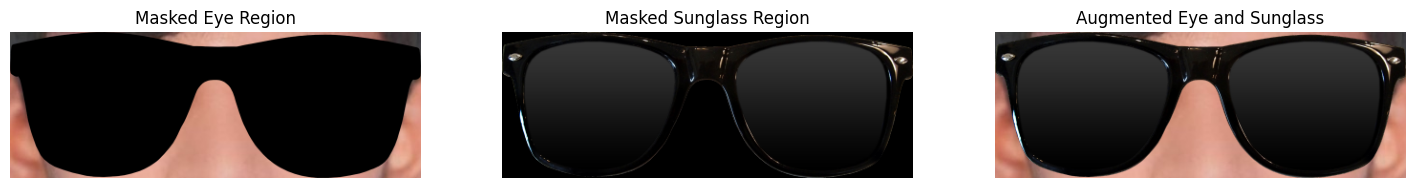

In [10]:
# Make the dimensions of the mask same as the input image (3 channels)
glassMask = cv2.merge((glassMask1, glassMask1, glassMask1))

# Convert alpha to a 0-1 floating-point mask for correct blending
glassMask = glassMask.astype(np.float32) / 255.0

# Get the eye region from the face image
faceWithGlassesArithmetic = faceImage.copy()
eyeROI = faceWithGlassesArithmetic[y1:y2, x1:x2].astype(np.float32)

# Blend the sunglasses with the eye region using the alpha mask
maskedEye = eyeROI * (1.0 - glassMask)
maskedGlass = glassBGR.astype(np.float32) * glassMask
eyeRoiFinal = np.clip(maskedEye + maskedGlass, 0, 255).astype(np.uint8)

# Display all intermediate results
plt.figure(figsize=[18, 6])
plt.subplot(131); plt.imshow(cv2.cvtColor(maskedEye.astype(np.uint8), cv2.COLOR_BGR2RGB)); plt.title("Masked Eye Region"); plt.axis('off')
plt.subplot(132); plt.imshow(cv2.cvtColor(maskedGlass.astype(np.uint8), cv2.COLOR_BGR2RGB)); plt.title("Masked Sunglass Region"); plt.axis('off')
plt.subplot(133); plt.imshow(cv2.cvtColor(eyeRoiFinal, cv2.COLOR_BGR2RGB)); plt.title("Augmented Eye and Sunglass"); plt.axis('off')
plt.show()

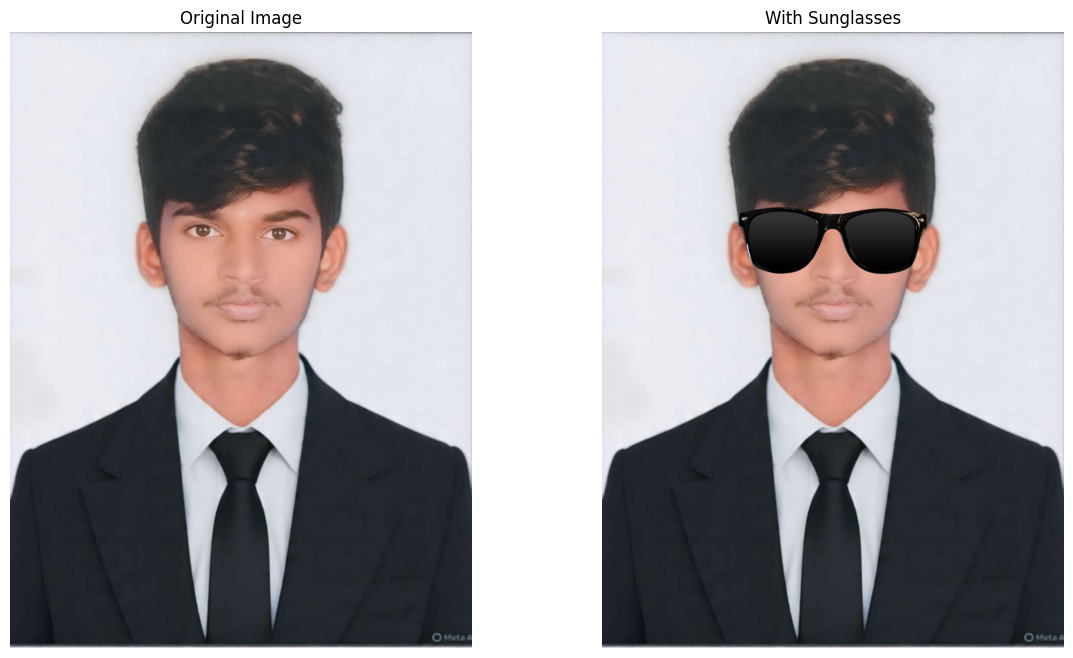

Saved: face_with_sunglasses.jpg


In [11]:
# Replace the eye ROI with the blended sunglasses
faceWithGlassesArithmetic[y1:y2, x1:x2] = eyeRoiFinal

# Display the original and final result
plt.figure(figsize=[14, 8])
plt.subplot(121); plt.imshow(cv2.cvtColor(faceImage, cv2.COLOR_BGR2RGB)); plt.title("Original Image"); plt.axis('off')
plt.subplot(122); plt.imshow(cv2.cvtColor(faceWithGlassesArithmetic, cv2.COLOR_BGR2RGB)); plt.title("With Sunglasses"); plt.axis('off')
plt.show()

# Save the final image without removing any notebook outputs
cv2.imwrite('face_with_sunglasses.jpg', faceWithGlassesArithmetic)
print("Saved: face_with_sunglasses.jpg")